## A Mathematical Introduction to Machine Learning (5MA206), HT26
# Computer lab 1, part B: principal component analysis

**Instructions**
* Work through the notebook from top to bottom. Complete the code cells marked `# EDIT`, and answer the numbered
  questions **Q1, Q2, …** in the text cells below them.
* You may work in pairs. Write both names below.
* Before you submit: restart the kernel and run all cells (*Kernel* menu), and check that the notebook runs from start to
  finish without errors.
* Lab 1 consists of part A (linear regression) and part B (this notebook). Submit both notebooks together as one zip file on Canvas.

**Names:** Marcus Boivie

PCA finds an $M$-dimensional subspace that the data lie close to (Lectures 5–6, MML Chapter 10). For **centred** data
$\boldsymbol x_1,\dots,\boldsymbol x_N\in\mathbb R^D$ (mean $\boldsymbol 0$) we

1. compute the data covariance matrix $\boldsymbol S=\frac1N\sum_{n=1}^N\boldsymbol x_n\boldsymbol x_n^\top$ and its
   eigenvalues $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_D\ge0$ with orthonormal eigenvectors
   $\boldsymbol u_1,\dots,\boldsymbol u_D$,
2. put the first $M$ eigenvectors as columns in $\boldsymbol B=[\boldsymbol u_1,\dots,\boldsymbol u_M]\in\mathbb R^{D\times M}$,
3. compute the **codes** $\boldsymbol z_n=\boldsymbol B^\top\boldsymbol x_n\in\mathbb R^M$ and the **reconstructions**
   $\tilde{\boldsymbol x}_n=\boldsymbol B\boldsymbol z_n=\boldsymbol B\boldsymbol B^\top\boldsymbol x_n$.

Among all $M$-dimensional subspaces this one gives the smallest average squared reconstruction error, and
$$
J_M=\frac1N\sum_{n=1}^N\|\boldsymbol x_n-\tilde{\boldsymbol x}_n\|^2=\sum_{m=M+1}^D\lambda_m
\qquad\text{(the variance in the discarded directions).}
$$

**Convention.** In code, a data set is stored with one example per **row**: $\boldsymbol X\in\mathbb R^{N\times D}$ has
the rows $\boldsymbol x_n^\top$. This is the transpose of the $D\times N$ matrix in MML Chapter 10 and in Lectures 5–6.
Then $\boldsymbol S=\frac1N\boldsymbol X^\top\boldsymbol X$, the codes are the rows of $\boldsymbol Z=\boldsymbol X\boldsymbol B$
($N\times M$), and the reconstructions are the rows of $\tilde{\boldsymbol X}=\boldsymbol Z\boldsymbol B^\top$ ($N\times D$).

**Packages.** The next cell installs the packages this lab needs, if they are missing (this needs an internet
connection). If they are already installed, as in Google Colab or a Miniforge environment set up as on the lab slides,
it only prints `Requirement already satisfied`. If it installed something new and an import below fails, restart the
kernel (*Kernel* menu) and run the notebook again.

In [1]:
# pandas is used by fetch_openml (no comments on the %pip line: Windows would pass them to pip)
%pip install numpy matplotlib scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
rng = np.random.default_rng(1)   # fixed seed: everybody gets the same data

## 1. PCA in two dimensions

We start with $N=200$ points in $\mathbb R^2$. First centre the data: compute the mean $\boldsymbol\mu$ (a vector with
$D=2$ entries) and subtract it from every row.

mean of the centred data: [1.17572618e-15 2.20934382e-16]


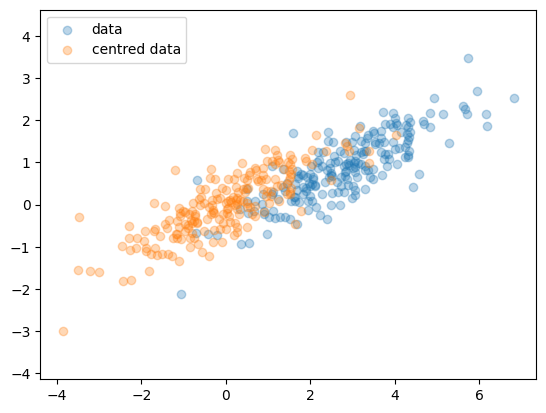

In [3]:
A = np.array([[1.5, 0.0], [0.8, 0.5]])
X_raw = rng.normal(size=(200, 2)) @ A.T + np.array([3.0, 1.0])
N, D = X_raw.shape

mu = np.mean(X_raw, axis=0)   # EDIT: the mean of the rows of X_raw (hint: np.mean with axis=0)
X = X_raw - mu        # centred data: every row minus mu
print('mean of the centred data:', X.mean(axis=0))

plt.figure()
plt.scatter(X_raw[:, 0], X_raw[:, 1], alpha=0.3, label='data')
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label='centred data')
plt.axis('equal'); plt.legend();

Complete the computation of $\boldsymbol S$. The function `np.linalg.eigh` computes the eigenvalues and orthonormal
eigenvectors of a symmetric matrix, with the eigenvalues in **increasing** order, so we reverse the order. The columns of
`U` are the eigenvectors $\boldsymbol u_1,\boldsymbol u_2$.

S =
 [[1.87285098 0.8945273 ]
 [0.8945273  0.62595195]]
eigenvalues: [2.33975387 0.15904905]
eigenvectors (columns):
 [[-0.88650639  0.46271635]
 [-0.46271635 -0.88650639]]
variance of the data along u_1: 2.3397538749347397


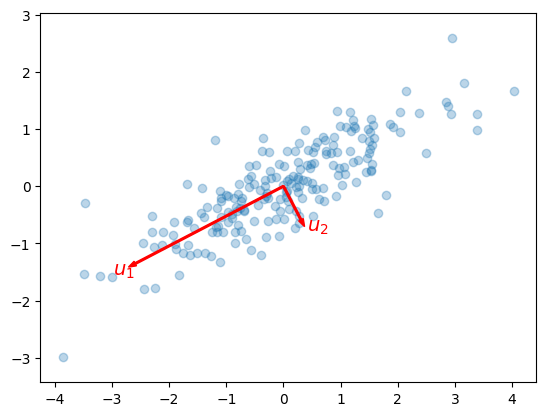

In [5]:
S = (X.T @ X) / N   # EDIT: the data covariance matrix (D x D)
lam, U = np.linalg.eigh(S)
lam, U = lam[::-1], U[:, ::-1]     # decreasing order
print('S =\n', S)
print('eigenvalues:', lam)
print('eigenvectors (columns):\n', U)

z1 = X @ U[:, 0]   # the coordinates of all points along u_1
print('variance of the data along u_1:', np.mean(z1**2))

plt.figure()
plt.scatter(X[:, 0], X[:, 1], alpha=0.3)
for m in range(2):
    v = 2*np.sqrt(lam[m])*U[:, m]    # arrow of length 2 standard deviations along u_m
    plt.arrow(0, 0, v[0], v[1], color='r', width=0.03, length_includes_head=True)
    plt.text(1.1*v[0], 1.1*v[1], f'$u_{m+1}$', color='r', fontsize=14)
plt.axis('equal');

**Q1.** What does the eigenvalue $\lambda_1$ tell you about the data, and how does the cell above confirm it? Why is
$\boldsymbol u_1$ the direction in which the data vary the most? (Lecture 5)

Answer

**Q1:** The eigenvalue $\lambda_1$ is large and represents the variance along the line $\boldsymbol u_1$, which tells us we are keeping much of the total variance. This is easily confirmed by observing the datapoints, which clearly lie scattered around that line, as well as the value printed out for the variance along $\boldsymbol u_1$ which matches $\lambda_1$. $\boldsymbol u_1$ is in the direction in which the data vary the most because when we compress the data onto one less dimension, we only get to keep one straight line. Since the variance along the line is a weighted average of the two eigenvalues, we choose the line with the largest eigenvalue to maximize the weight on it and to keep the largest variance.

### Codes and reconstructions
Now use only $M=1$ component. Complete the code for $\boldsymbol B$, the codes $\boldsymbol Z$ and the
reconstructions $\tilde{\boldsymbol X}$ (see the convention above), and compute the reconstruction error $J_1$.

In [ ]:
M = 1
B = ...       # EDIT: the first M eigenvectors (D x M)
Z = ...       # EDIT: the codes (N x M)
X_rec = ...   # EDIT: the reconstructions (N x D)

J = np.mean(np.sum((X - X_rec)**2, axis=1))   # (1/N) sum_n ||x_n - x~_n||^2
print(f'J_1 = {J:.4f}')
print('eigenvalues:', lam)

plt.figure()
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label='data')
plt.scatter(X_rec[:, 0], X_rec[:, 1], alpha=0.3, label='reconstructions')
for n in range(0, N, 10):   # every 10th point and its reconstruction
    plt.plot([X[n, 0], X_rec[n, 0]], [X[n, 1], X_rec[n, 1]], 'k-', lw=0.8)
plt.axis('equal'); plt.legend();

**Q2.** Which eigenvalue is $J_1$ equal to, and why? Why are the black line segments (from $\boldsymbol x_n$ to
$\tilde{\boldsymbol x}_n$) perpendicular to $\boldsymbol u_1$? (Lectures 5–6)

*Write your answer here.*

### A PCA routine
Collect the steps in a function. It is used for the rest of the lab.

In [ ]:
def pca(X, M):
    # X: centred data (N x D), one example per row.  M: the number of components.
    # Returns B (D x M), whose columns are the first M principal directions, and
    # lam, all D eigenvalues of S in decreasing order.
    N, D = X.shape
    S = ...                  # EDIT
    lam, U = np.linalg.eigh(S)
    lam, U = lam[::-1], U[:, ::-1]
    lam = np.maximum(lam, 0)    # zero eigenvalues can come out as -1e-17 because of rounding
    B = ...                  # EDIT
    return B, lam

B, lam = pca(X, 1)
print(B.ravel(), lam)    # should agree with the results above (B may have the opposite sign)

## 2. Units and standardisation

PCA depends on the units of the features. Here are (synthetic) heights in metres and weights in kilograms of 200
people. Complete `standardize`, which divides every centred feature by its standard deviation.

In [ ]:
height = 1.75 + 0.10*rng.normal(size=200)                        # metres
weight = 75 + 50*(height - 1.75) + 8*rng.normal(size=200)       # kilograms

def centre(X):
    return X - X.mean(axis=0)

def standardize(X):
    # centre every feature (column) and divide it by its standard deviation
    return ...   # EDIT (hint: X.std(axis=0))

def plot_pc(ax, X, title):
    B, lam = pca(X, 2)
    ax.scatter(X[:, 0], X[:, 1], alpha=0.3)
    for m in range(2):
        v = 2*np.sqrt(lam[m])*B[:, m]
        ax.arrow(0, 0, v[0], v[1], color='r', width=0.01*np.sqrt(lam[0]), length_includes_head=True)
    ax.set_title(title + f'\n$u_1$ = ({B[0, 0]:.3f}, {B[1, 0]:.3f})'); ax.axis('equal')

print(f'variances: height {height.var():.4f} m^2 = {(100*height).var():.1f} cm^2, weight {weight.var():.1f} kg^2')
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
plot_pc(ax[0], centre(np.column_stack([height, weight])), 'm and kg, centred')
plot_pc(ax[1], centre(np.column_stack([100*height, weight])), 'cm and kg, centred')
plot_pc(ax[2], standardize(np.column_stack([height, weight])), 'standardised')
ax[0].set_xlabel('height'); ax[0].set_ylabel('weight');

**Q3.** Explain the direction of $\boldsymbol u_1$ in each of the three plots. Why does the first principal component
follow the weight when height is measured in metres? What changes in centimetres, and what happens to the standardised
data if you change the units? When should you standardise before PCA? (Lecture 6)

*Write your answer here.*

## 3. Handwritten digits (MNIST)

MNIST consists of $70\,000$ greyscale images of handwritten digits, $28\times28$ pixels, so $D=784$. The first
$60\,000$ are the official training set. The next cell downloads the data (about 15 MB) from openml.org, which can take
a minute; scikit-learn stores a copy on your computer, so it is fast the next time.

In [ ]:
from sklearn.datasets import fetch_openml
images, labels = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
print(images.shape, labels[:10])    # the labels are strings '0', ..., '9'

We use the first $N=1000$ images, with the pixel values scaled to $[0,1]$, and centre them. The mean $\boldsymbol\mu$ is
itself an image.

In [ ]:
N_img = 1000
X_img = images[:N_img] / 255
y_img = labels[:N_img]
mu_img = X_img.mean(axis=0)
X = X_img - mu_img          # centred data, N x 784

def show(ax, x, title=''):
    ax.imshow(x.reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(title); ax.axis('off')

fig, ax = plt.subplots(1, 9, figsize=(15, 2))
for i in range(8):
    show(ax[i], X_img[i], y_img[i])
show(ax[8], mu_img, 'mean $\\mu$')

print('number of pixels that are 0 in all 1000 images:', np.sum(X_img.std(axis=0) == 0))

**Q4.** In Section 2 we standardised the features. Why is it better not to standardise the pixels here? (Look at the
output of the cell above.)

*Write your answer here.*

### How many components?
The fraction of the variance kept by $M$ components is $V_M/V_D=\sum_{m\le M}\lambda_m\big/\sum_{m=1}^D\lambda_m$.
Find the smallest $M$ that keeps 90% and 99% of the variance.

In [ ]:
B, lam = pca(X, 784)               # all 784 principal directions
frac = np.cumsum(lam) / np.sum(lam)   # frac[M-1] = V_M / V_D
M90 = ...   # EDIT: the smallest M with frac[M-1] >= 0.9 (hint: np.argmax of a boolean array)
M99 = ...   # EDIT
print('M for 90%:', M90, '   M for 99%:', M99)
print('number of eigenvalues > 1e-10:', np.sum(lam > 1e-10))

Ms = np.arange(1, 785)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(Ms, lam + 1e-20); ax[0].set_ylim(1e-8, 10)
ax[0].set_xlabel('$m$'); ax[0].set_title('eigenvalues $\\lambda_m$')
ax[1].plot(Ms, frac); ax[1].axhline(0.9, ls='--', c='gray'); ax[1].axhline(0.99, ls=':', c='gray')
ax[1].set_xlabel('$M$'); ax[1].set_title('fraction of the variance kept, $V_M/V_D$');

**Q5.** How many components keep 90% and 99% of the variance? Many of the 784 eigenvalues are zero (up to rounding).
Why? (Hint: what is $\boldsymbol S\boldsymbol e_d$ if pixel $d$ is $0$ in every image?)

*Write your answer here.*

### Reconstruction error, on the data and on new images
The formula $J_M=\sum_{m>M}\lambda_m$ gives the reconstruction error for every $M$ at once. Check it by computing $J_M$
directly from the reconstructions for some values of $M$. Then compute the error for $1000$ **new** images (from the
official test set), reconstructed with the **same** $\boldsymbol\mu$ and $\boldsymbol B$.

In [ ]:
J_eig = np.sum(lam) - np.cumsum(lam)       # J_eig[M-1] = sum of lambda_m for m > M

X_new = images[60000:61000] / 255 - mu_img   # new images, centred with the mean of the old ones

M_list = [1, 2, 5, 10, 20, 50, 100, 200, 400, 600, 784]
J_direct, J_new = [], []
for M in M_list:
    B_M = B[:, :M]
    X_rec = ...     # EDIT: reconstructions of X with M components
    X_new_rec = ... # EDIT: reconstructions of X_new with M components
    J_direct.append(np.mean(np.sum((X - X_rec)**2, axis=1)))
    J_new.append(np.mean(np.sum((X_new - X_new_rec)**2, axis=1)))
    print(f'M = {M:3d}:  sum of discarded eigenvalues {J_eig[M-1]:.4f},  J_M {J_direct[-1]:.4f},  new images {J_new[-1]:.4f}')

plt.figure()
plt.plot(Ms, J_eig, label='$\\sum_{m>M}\\lambda_m$')
plt.plot(M_list, J_direct, 'o', label='$J_M$ computed directly')
plt.plot(M_list, J_new, 's-', label='new images')
plt.xlabel('$M$'); plt.ylabel('mean squared reconstruction error'); plt.legend();

**Q6.** Do the two ways of computing $J_M$ agree? Why is the error for the new images larger? Explain in particular why
it is not $0$ for $M=600$, and why it is $0$ for $M=784$. (Compare with training and test error in Lectures 2 and 4.)

*Write your answer here.*

### What the reconstructions look like
Each row shows one image, then its reconstructions $\boldsymbol\mu+\tilde{\boldsymbol x}_n$ with $M$ components.

In [ ]:
M_show = [1, 2, 5, 10, 20, 50, M90, M99]
idx = [list(y_img).index(str(d)) for d in range(10)]   # the first image of every digit
fig, ax = plt.subplots(len(idx), len(M_show) + 1, figsize=(1.4*(len(M_show) + 1), 1.5*len(idx)))
for r, n in enumerate(idx):
    show(ax[r, 0], X_img[n], 'original' if r == 0 else '')
    for c, M in enumerate(M_show):
        x_rec = mu_img + X[n] @ B[:, :M] @ B[:, :M].T
        show(ax[r, c + 1], np.clip(x_rec, 0, 1), f'M = {M}' if r == 0 else '')
plt.tight_layout()

The principal directions $\boldsymbol u_m$ are also images ("eigendigits"). Red pixels are positive and blue pixels
negative; the code $z_m=\boldsymbol u_m^\top\boldsymbol x$ is large when the centred image looks like $\boldsymbol u_m$.

In [ ]:
fig, ax = plt.subplots(1, 8, figsize=(15, 2))
for m in range(8):
    a = np.abs(B[:, m]).max()
    ax[m].imshow(B[:, m].reshape(28, 28), cmap='bwr', vmin=-a, vmax=a)
    ax[m].set_title(f'$u_{{{m+1}}}$, $\\lambda$ = {lam[m]:.2f}'); ax[m].axis('off')

**Q7.** How many components do you need before you can recognise all ten digits in the reconstructions? Which digits
are reconstructed well with very few components, and which need many? Is keeping 90% of the variance enough to
recognise the digits?

*Write your answer here.*

## 4. Two-dimensional codes

With $M=2$, every image is represented by two numbers $(z_1,z_2)$, so the whole data set can be plotted
(compare MML Figure 10.10). Here are all $1000$ images, coloured by their label.

In [ ]:
Z = X @ B[:, :2]
plt.figure(figsize=(8, 6))
for d in range(10):
    plt.scatter(Z[y_img == str(d), 0], Z[y_img == str(d), 1], s=12, alpha=0.6, color=plt.cm.tab10(d), label=str(d))
plt.xlabel('$z_1$'); plt.ylabel('$z_2$'); plt.legend(markerscale=2);

Plot two of the digits at a time. Change the pair and rerun the cell.

In [ ]:
a, b = '3', '5'    # try different pairs
plt.figure()
plt.scatter(Z[y_img == a, 0], Z[y_img == a, 1], alpha=0.5, label=a)
plt.scatter(Z[y_img == b, 0], Z[y_img == b, 1], alpha=0.5, label=b)
plt.xlabel('$z_1$'); plt.ylabel('$z_2$'); plt.legend();

**Q8.** A classifier must separate the points of different classes. Which pair of digits is easiest to separate using
only $(z_1,z_2)$, and which pair is hard? Show the plot for your easiest pair, and explain it with the images
$\boldsymbol u_1$ and $\boldsymbol u_2$ above.

**Q9.** PCA does not use the labels. Is the best 2-dimensional subspace for reconstruction (PCA) necessarily the best one
for separating two classes? Explain briefly.

*Write your answer here.*

## Optional extras
* Repeat Section 3 with all $60\,000$ training images (computing $\boldsymbol S$ takes a few seconds). How do $M_{90}$
  and the error for new images change?
* Compute the principal directions with the SVD of $\boldsymbol X$ (`np.linalg.svd`, Lecture 6) and compare with `eigh`.
* Compare with `sklearn.decomposition.PCA`.